<a href="https://colab.research.google.com/github/andreeus3/neural-network/blob/main/Practice_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IMPORTACIÓN DE LIBRERIAS PARA PYTHON

In [6]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
import torch
from torch import nn
import seaborn as sns

# CARGA DE DATOS DESDE GOOGLE DRIVE DE LAS IMAGENENES Y ENTRENAMIENTOS

In [2]:
from google.colab import drive

system_mount = False
try:
    drive.mount('/content/drive')
except Exception:
    pass

PATH_IMAGES =  "/content/drive/MyDrive/Colab_Notebooks/data_set/Image/train-images.idx3-ubyte"
PATH_LABELS =  "/content/drive/MyDrive/Colab_Notebooks/data_set/Label/train-labels.idx1-ubyte"



Mounted at /content/drive


# APLANAMIENTO DE LAS IMAGENES Y SEGMENTO DE LOS DATOS DE ENTRENAMIENTO

* Se decidio aplanar las imagenes a un formato de 28*28 = 784 px
* Se toma un sesgo de 10.000 datos para el entrenamiento y validación


In [3]:
with open(PATH_IMAGES, "rb") as f:
    f.read(16)
    X = np.frombuffer(f.read(), dtype=np.uint8)
    X = X.reshape(-1, 28, 28) / 255.0
    with open(PATH_LABELS, "rb") as f:
        f.read(8)
        y = np.frombuffer(f.read(), dtype=np.uint8)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=10_000, random_state=42, stratify=y)


torch.manual_seed(42) # fija los pesos iniciales
g = torch.Generator().manual_seed(42) # fija el orden de los lotes
train_ds = TensorDataset(torch.tensor(X_train.reshape(-1, 784), dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
X_train = X_train.reshape(-1, 784)
yt_train = torch.nn.functional.one_hot(
    torch.tensor(y_train, dtype=torch.long),
    num_classes=10
).numpy()

X_val = X_val.reshape(10000, 784)

yt_val = torch.nn.functional.one_hot(
    torch.tensor(y_val, dtype=torch.long),
    num_classes=10
    ).numpy()

# INICIALIZACIÓN DE PESOS

Se Decidio realizar una red neuronal con las siguientes caracteristicas

1. Una capa inicial con 50.000 datos de entrada y 784 datos de salida
2. Una primera capa oculta con 784 neuronas de entrada y 100 neuronas de salida
3.

# IMPLEMENTACIÓN DE REDES NEURONALES CON ARQUITECTURA



*   **RELU** - Como funcion de activación porque su entrenamiento suele ser más rapido

*   **SOFTMAX** - Para la capa de salida debido a que fuerza que las salidas de la red representen una distribución de probabilidad.

* **CATEGORICAL CROSS-ENTROPY** - Para calcular la perdida, al combinarse con la función de activación Softmax, su derivada se vuelve muy sencilla y lineal. Esto evita que el aprendizaje se estanque y acelera la convergencia del modelo.\

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


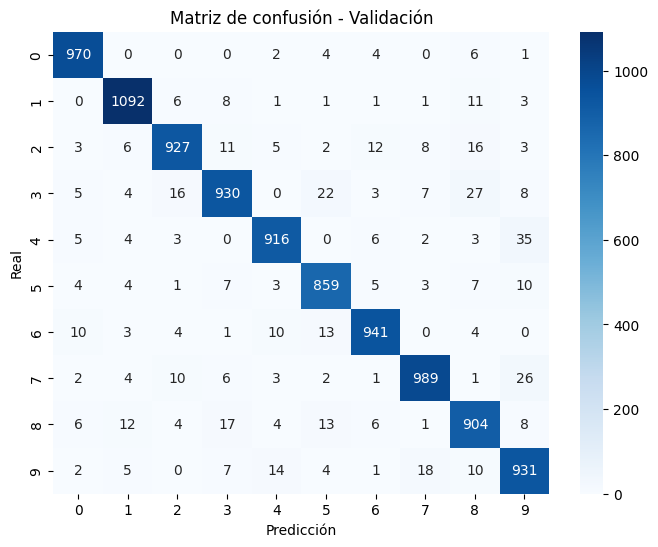


 Classification Report (Validación):
              precision    recall  f1-score   support

           0     0.9633    0.9828    0.9729       987
           1     0.9630    0.9715    0.9672      1124
           2     0.9547    0.9335    0.9440       993
           3     0.9422    0.9100    0.9258      1022
           4     0.9562    0.9405    0.9482       974
           5     0.9337    0.9513    0.9424       903
           6     0.9602    0.9544    0.9573       986
           7     0.9611    0.9473    0.9542      1044
           8     0.9141    0.9272    0.9206       975
           9     0.9083    0.9385    0.9232       992

    accuracy                         0.9459     10000
   macro avg     0.9457    0.9457    0.9456     10000
weighted avg     0.9461    0.9459    0.9459     10000

y_val: (10000,)
y_pred: (10000,)
Accuracy full train [50.000] 0.990434
Accuracy Validation: [10.000] 0.9459


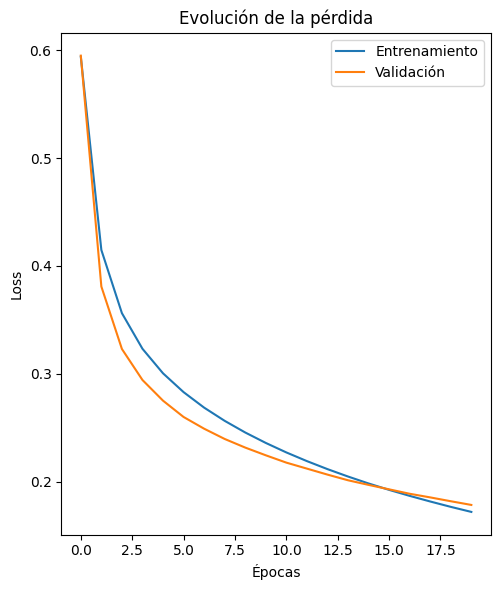

In [8]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
import torch
from torch import nn
import seaborn as sns

from google.colab import drive

system_mount = False
try:
    drive.mount('/content/drive')
except Exception:
    pass


PATH_IMAGES =  "/content/drive/MyDrive/Colab_Notebooks/data_set/Image/train-images.idx3-ubyte"
PATH_LABELS =  "/content/drive/MyDrive/Colab_Notebooks/data_set/Label/train-labels.idx1-ubyte"



with open(PATH_IMAGES, "rb") as f:
    f.read(16)
    X = np.frombuffer(f.read(), dtype=np.uint8)
    X = X.reshape(-1, 28, 28) / 255.0
    with open(PATH_LABELS, "rb") as f:
        f.read(8)
        y = np.frombuffer(f.read(), dtype=np.uint8)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=10_000, random_state=42, stratify=y)


torch.manual_seed(42) # fija los pesos iniciales
g = torch.Generator().manual_seed(42) # fija el orden de los lotes
train_ds = TensorDataset(torch.tensor(X_train.reshape(-1, 784), dtype=torch.float32), torch.tensor(y_train, dtype=torch.long))
X_train = X_train.reshape(-1, 784)
yt_train = torch.nn.functional.one_hot(
    torch.tensor(y_train, dtype=torch.long),
    num_classes=10
).numpy()

X_val = X_val.reshape(10000, 784)

yt_val = torch.nn.functional.one_hot(
    torch.tensor(y_val, dtype=torch.long),
    num_classes=10
    ).numpy()



SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
learning_rate = 0.01
train_losses = []
validation_losses = []




#Capa oculta - inicializacion
W1 = np.random.randn(784, 100) * np.sqrt(2/728) # 784 entradas y 100 salidas que son mis 100 neuronas
b1 = np.zeros(100)

#Segunda capa oculta
W2 = np.random.randn(100, 50) * np.sqrt(2/100) #
b2 = np.zeros(50)

#Capa de salida  - Inicializacion
W3 = np.random.randn(50, 10) * np.sqrt(2/50) # La inicialización de He si porque estoy usndo ReLU para capa oculta
b3 = np.zeros(10)

#Perceptron

def relu (Z): #Para la capa oculta
  return np.maximum(0,Z)

def softmax(Z): # Para la capa de salida
    expZ = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return expZ / np.sum(expZ, axis=1, keepdims=True)

def categorical_entropy(Y, A): #Funcion de perdida

    epsilon = 1e-15
    A = np.clip(A, epsilon, 1 - epsilon)

    return -np.mean(np.sum(Y * np.log(A), axis=1))


batch_size = 128 # un buen punto de partida

epochs = 20
m = yt_train.shape[0]


for epoch in range(epochs):
  for i in range(0, m, batch_size):
    # Forward propagation

    X_batch = X_train[i:i + batch_size]
    y_batch = yt_train[i:i + batch_size]

    mb = X_batch.shape[0]

    Z1 = np.dot(X_batch, W1) + b1
    A1 = relu(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = relu(Z2)

    Z3 = np.dot(A2, W3) + b3
    A3 = softmax(Z3)  #Usamos softmax para capas de salida

    loss_batch = categorical_entropy(y_batch, A3)


    #Backpropagation

    dZ3 = A3 - y_batch
    dW3 = np.dot(A2.T, dZ3) / mb
    db3 = np.sum(dZ3, axis=0) / mb

    #segunda capa oculta
    dA2 = np.dot(dZ3, W3.T)
    dZ2 = dA2 * (Z2 > 0)


    dW2 = np.dot(A1.T, dZ2) / mb
    db2 = np.sum(dZ2, axis=0) / mb

    #primera capa oculta

    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * (Z1 > 0)

    dW1 = np.dot(X_batch.T, dZ1) / mb
    db1 = np.sum(dZ1, axis=0) /mb


    #Actualizamos los pesos

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W3 -= learning_rate * dW3
    b3 -= learning_rate * db3

  #Validacion

  Z1_val = np.dot(X_val, W1)+ b1
  A1_val = relu(Z1_val)

  Z2_val = np.dot(A1_val, W2) + b2
  A2_val = relu(Z2_val)

  Z3_val = np.dot(A2_val, W3) + b3
  A3_val = softmax(Z3_val)


  Z1 = np.dot(X_train, W1) + b1
  A1 = relu(Z1)

  Z2 = np.dot(A1, W2) + b2
  A2 = relu(Z2)

  Z3 = np.dot(A2, W3) + b3
  A3 = softmax(Z3)  #Usamos softmax para capas de salid

  loss_val = categorical_entropy(yt_val, A3_val)

  loss_train = categorical_entropy(yt_train, A3)



  y_pred_val = np.argmax(A3_val, axis=1)


  y_pred_train = np.argmax(A3, axis=1)


  validation_losses.append(loss_batch)
  train_losses.append(loss_train) # Guarda la perdida por epoca y no toda la matriz

  prediction = (A3 >= 0.5).astype(int)



  train_accuracy = np.mean(prediction == yt_train)
  val_accuracy = np.mean(y_pred_val == y_val)


cm = confusion_matrix(y_val, y_pred_val)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de confusión - Validación")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()


#print("Matriz de Confusión:")
#print(confusion_matrix(y_val, y_pred))

print("\n Classification Report (Validación):")
print(classification_report(y_val, y_pred_val, digits=4))



print("y_val:", y_val.shape)
print("y_pred:", y_pred_val.shape)

print("Accuracy full train [50.000]", train_accuracy)

print("Accuracy Validation: [10.000]", val_accuracy)


plt.figure(figsize=(14,6))

plt.subplot(1,3,1)
plt.plot(train_losses, label='Entrenamiento')
plt.plot(validation_losses, label='Validación')
plt.title('Evolución de la pérdida')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()


plt.tight_layout()
plt.show()

